# **0. Cellule Initiale : Montage de Google Drive**

In [ ]:
from google.colab import drive
import os

print("## Cellule Initiale : Montage de Google Drive")

# ================== MONTAGE GOOGLE DRIVE ==================
# Tente de monter Google Drive.
# Ceci est nécessaire pour accéder à vos données et sauvegarder les résultats.
try:
    drive.mount('/content/drive')
    print("✅ Google Drive monté avec succès.")
except Exception as e:
    print(f"❌ Erreur lors du montage de Google Drive : {e}")
    print("Veuillez essayer de monter le Drive manuellement en cliquant sur l'icône 'Dossiers' (📁) à gauche, puis sur l'icône 'Mount Drive' (le triangle avec la flèche).")

# Vous pouvez ajouter ici une vérification rapide de l'existence de votre dossier dataset
dataset_path = "/content/drive/MyDrive/DataSets" # Mettez ici le chemin de votre dataset
if os.path.exists(dataset_path):
    print(f"✅ Dossier du dataset trouvé à: {dataset_path}")
else:
    print(f"⚠️ Dossier du dataset non trouvé à: {dataset_path}")
    print("Veuillez vérifier le chemin ou monter manuellement Google Drive.")


print("\n--- Cellule Initiale terminée ---")

## Cellule Initiale : Montage de Google Drive
Mounted at /content/drive
✅ Google Drive monté avec succès.
✅ Dossier du dataset trouvé à: /content/drive/MyDrive/DataSets

--- Cellule Initiale terminée ---


# **Partie 1 : Analyse des Données**

## Partie 1 : Analyse des Données
✅ Dossier du dataset trouvé: /content/drive/MyDrive/DataSets

Analyse de la structure des dossiers...
  - train: 4 classes trouvées.
  - valid: 4 classes trouvées.
  - test: 4 classes trouvées.

Nombre d'images par classe dans chaque sous-dossier:

--- train ---
  Corn___taches: 1248 images
  Corn___saine: 2460 images
  Corn___ brûlure: 2437 images
  Corn___rouille_commune: 2711 images

--- valid ---
  Corn___rouille_commune: 289 images
  Corn___ brûlure: 231 images
  Corn___saine: 230 images
  Corn___taches: 105 images

--- test ---
  Corn___taches: 59 images
  Corn___rouille_commune: 120 images
  Corn___ brûlure: 102 images
  Corn___saine: 112 images

Visualisation de la distribution des classes (ensemble d'entraînement)...


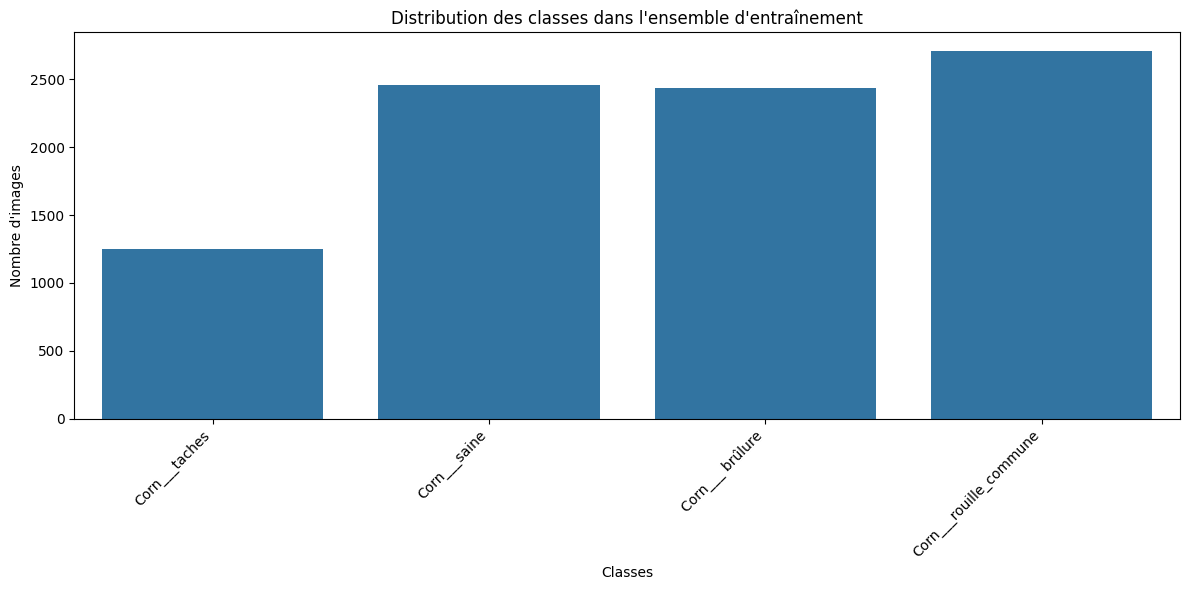


--- Analyse des Données terminée ---


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("## Partie 1 : Analyse des Données")

# ================= CHEMIN DU DATASET =================
# Remplacez '/content/drive/MyDrive/plantes_dataset/Dataset_Organized' par le chemin réel de votre dossier "DataSets"
base_data_dir = "/content/drive/MyDrive/DataSets"

# Vérifier si le dossier existe
if not os.path.exists(base_data_dir):
    print(f"❌ ERREUR: Le dossier du dataset est introuvable: {base_data_dir}")
    raise FileNotFoundError(f"Dossier du dataset manquant: {base_data_dir}")
else:
    print(f"✅ Dossier du dataset trouvé: {base_data_dir}")

# ================= ANALYSE DE LA STRUCTURE DES DOSSIERS =================
print("\nAnalyse de la structure des dossiers...")

# Utilisation des noms de dossiers en minuscules
subdirs = ['train', 'valid', 'test']
data_structure = {}

for subdir in subdirs:
    subdir_path = os.path.join(base_data_dir, subdir)
    if os.path.exists(subdir_path):
        classes = [d for d in os.listdir(subdir_path) if os.path.isdir(os.path.join(subdir_path, d))]
        data_structure[subdir] = {c: len(os.listdir(os.path.join(subdir_path, c))) for c in classes}
        print(f"  - {subdir}: {len(classes)} classes trouvées.")
    else:
        print(f"  - ⚠️ Dossier '{subdir}' non trouvé à {subdir_path}. Il sera ignoré.")
        data_structure[subdir] = {}

# Afficher le nombre d'images par classe dans chaque sous-dossier
print("\nNombre d'images par classe dans chaque sous-dossier:")
for subdir, classes_info in data_structure.items():
    print(f"\n--- {subdir} ---")
    if classes_info:
        for class_name, count in classes_info.items():
            print(f"  {class_name}: {count} images")
    else:
        print("  Aucune classe trouvée.")

# ================= VISUALISATION DE LA DISTRIBUTION DES CLASSES =================
print("\nVisualisation de la distribution des classes (ensemble d'entraînement)...")

if 'train' in data_structure and data_structure['train']:
    train_class_counts = data_structure['train']
    class_names = list(train_class_counts.keys())
    counts = list(train_class_counts.values())

    plt.figure(figsize=(12, 6))
    sns.barplot(x=class_names, y=counts)
    plt.xticks(rotation=45, ha='right')
    plt.xlabel("Classes")
    plt.ylabel("Nombre d'images")
    plt.title("Distribution des classes dans l'ensemble d'entraînement")
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ Aucune donnée d'entraînement trouvée ou format incorrect pour la visualisation.")


print("\n--- Analyse des Données terminée ---")

# **Partie 2 : Préparation et Chargement des Données**

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

print("## Partie 2 : Préparation et Chargement des Données")

# ================= CONFIGURATION DES DONNÉES =================
# Chemins des données (assurez-vous que ces chemins sont corrects)
# Ces chemins pointent vers les dossiers d'entraînement, de validation et de test.
base_data_dir = "/content/drive/MyDrive/DataSets" # Assurez-vous que c'est le bon chemin pour votre nouveau dataset
train_dir = os.path.join(base_data_dir, "train")
valid_dir = os.path.join(base_data_dir, "valid")
test_dir = os.path.join(base_data_dir, "test") # Utilisé pour l'évaluation finale

# Vérification rapide des chemins pour s'assurer que les dossiers existent
if not os.path.exists(train_dir):
    print(f"❌ ERREUR: Le dossier d'entraînement est introuvable: {train_dir}")
    raise FileNotFoundError(f"Dossier d'entraînement manquant: {train_dir}")

if not os.path.exists(valid_dir):
    print(f"❌ ERREUR: Le dossier de validation est introuvable: {valid_dir}")
    raise FileNotFoundError(f"Dossier de validation manquant: {valid_dir}")

if not os.path.exists(test_dir):
    print(f"❌ ERREUR: Le dossier de test est introuvable: {test_dir}")
    raise FileNotFoundError(f"Dossier de test manquant: {test_dir}")


print("✅ Chemins des données vérifiés.")


# Paramètres
# img_size: La taille à laquelle les images seront redimensionnées.
img_size = (150, 150) # Vous pouvez ajuster cette taille
# batch_size: Le nombre d'images traitées à la fois par le modèle.
batch_size = 32

# Déterminer le nombre de classes automatiquement
classes_in_train = [d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))]
classes_in_train.sort() # Tri pour assurer un ordre constant
num_classes = len(classes_in_train)
print(f"Nombre total de classes détectées : {num_classes}")
print(f"Classes détectées : {classes_in_train}")


# ================= AUGMENTATION DES DONNÉES =================
print("\nConfiguration de l'augmentation des données...")
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    vertical_flip=False,
    brightness_range=[0.9, 1.1],
    channel_shift_range=20,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255) # Pas d'augmentation pour les données de validation et de test, seulement le rescale


# ================= CRÉATION DES GÉNÉRATEURS =================
print("\nCréation des générateurs de données...")
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical', # Utilisation de 'categorical' car c'est un problème de classification multi-classes
    classes=classes_in_train, # Spécifie explicitement les classes détectées
    shuffle=True,
    seed=42
)

validation_generator = test_datagen.flow_from_directory(
    valid_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    classes=classes_in_train, # Spécifie explicitement les classes détectées
    shuffle=False # Pas besoin de mélanger les données de validation
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    classes=classes_in_train, # Spécifie explicitement les classes détectées
    shuffle=False # Pas besoin de mélanger les données de test
)

# Vérification des classes détectées par les générateurs
class_names = list(train_generator.class_indices.keys())
print("\nClasses détectées par les générateurs:", class_names)
print(f"Nombre total d'images d'entraînement trouvées: {train_generator.samples}")
print(f"Nombre d'images de validation trouvées: {validation_generator.samples}")
print(f"Nombre d'images de test trouvées: {test_generator.samples}")


# Calculer les steps_per_epoch et validation_steps
steps_per_epoch_train = train_generator.samples // batch_size
if train_generator.samples % batch_size != 0:
    steps_per_epoch_train += 1

steps_per_epoch_val = validation_generator.samples // batch_size
if validation_generator.samples % batch_size != 0:
    steps_per_epoch_val += 1

steps_per_epoch_test = test_generator.samples // batch_size
if test_generator.samples % batch_size != 0:
    steps_per_epoch_test += 1


print("\n✅ Préparation et chargement des données terminés.")
print(f"   steps_per_epoch_train calculé: {steps_per_epoch_train}")
print(f"   steps_per_epoch_val calculé: {steps_per_epoch_val}")
print(f"   steps_per_epoch_test calculé: {steps_per_epoch_test}")

print("\n--- Partie 2 terminée ---")

## Partie 2 : Préparation et Chargement des Données
✅ Chemins des données vérifiés.
Nombre total de classes détectées : 4
Classes détectées : ['Corn___ brûlure', 'Corn___rouille_commune', 'Corn___saine', 'Corn___taches']

Configuration de l'augmentation des données...

Création des générateurs de données...
Found 8856 images belonging to 4 classes.
Found 855 images belonging to 4 classes.
Found 393 images belonging to 4 classes.

Classes détectées par les générateurs: ['Corn___ brûlure', 'Corn___rouille_commune', 'Corn___saine', 'Corn___taches']
Nombre total d'images d'entraînement trouvées: 8856
Nombre d'images de validation trouvées: 855
Nombre d'images de test trouvées: 393

✅ Préparation et chargement des données terminés.
   steps_per_epoch_train calculé: 277
   steps_per_epoch_val calculé: 27
   steps_per_epoch_test calculé: 13

--- Partie 2 terminée ---


## Visualisation d'exemples d'images augmentées
Affichage de 8 exemples d'images augmentées...


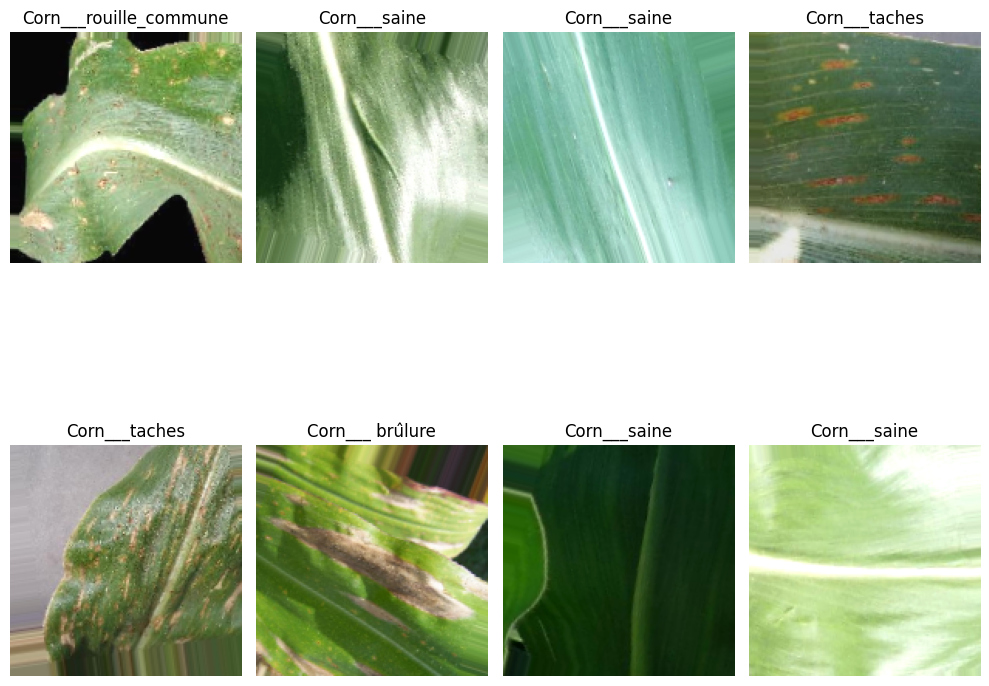


✅ Visualisation terminée.

--- Cellule de Visualisation terminée ---


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("## Visualisation d'exemples d'images augmentées")

# Assurez-vous que train_datagen et train_generator sont définis (Partie 2)
if 'train_datagen' not in locals() or 'train_generator' not in locals():
    print("❌ ERREUR: train_datagen ou train_generator non trouvé. Veuillez exécuter la Partie 2.")
else:
    # Récupérer un lot d'images et d'étiquettes du générateur
    # Important : utiliser flow() ou flow_from_directory() pour obtenir des images augmentées
    # Nous allons ici prendre un lot du train_generator qui utilise train_datagen
    try:
        # Obtenir un lot d'images et d'étiquettes
        images, labels = next(train_generator)

        print(f"Affichage de {min(len(images), 8)} exemples d'images augmentées...")

        # Afficher quelques images du lot (par exemple, les 8 premières)
        plt.figure(figsize=(10, 10))
        for i in range(min(len(images), 8)): # Afficher jusqu'à 8 images
            plt.subplot(int(np.ceil(min(len(images), 8) / 4)), 4, i + 1)
            # Afficher l'image. Les images sont déjà normalisées [0, 1] par le générateur.
            plt.imshow(images[i])
            # Trouver le nom de la classe (si class_names est disponible)
            if 'class_names' in locals():
                 class_index = np.argmax(labels[i])
                 plt.title(class_names[class_index])
            else:
                 plt.title(f"Classe: {np.argmax(labels[i])}")
            plt.axis('off')
        plt.tight_layout()
        plt.show()

        print("\n✅ Visualisation terminée.")

    except Exception as e:
        print(f"❌ Erreur lors de la récupération et de l'affichage des images augmentées: {e}")
        print("Veuillez vérifier la configuration de votre train_generator.")

print("\n--- Cellule de Visualisation terminée ---")

# **Partie 3 : Construction du Modèle**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2

print("## Partie 3 : Construction du Modèle")

# ================= CONSTRUCTION DU MODÈLE =================
print("Construction d'un modèle CNN simple...")

# Utilisation de Sequential pour construire un modèle couche par couche
model = Sequential([
    # Première couche de convolution
    Conv2D(32, (3, 3), activation='relu', input_shape=(img_size[0], img_size[1], 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Deuxième couche de convolution
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Troisième couche de convolution
    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Aplatir les couches de convolution pour les connecter aux couches Dense
    Flatten(),

    # Couches Dense (fully connected)
    Dense(512, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.5),

    # Couche de sortie
    Dense(num_classes, activation='softmax') # Utilise num_classes détecté en Partie 2
])

# Compiler le modèle
# Utilisation de l'optimiseur Adam avec un learning rate initial
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy', # Adapté pour la classification multi-classes avec one-hot encoding (categorical)
    metrics=['accuracy']
)

# Afficher un résumé du modèle
model.summary()

print("\n✅ Modèle construit et compilé.")
print("\n--- Partie 3 terminée ---")

## Partie 3 : Construction du Modèle
Construction d'un modèle CNN simple...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 148, 148, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 72, 72, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 34, 34, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,038,660 (72.63 MB)

 Trainable params: 19,037,188 (72.62 MB)

 Non-trainable params: 1,472 (5.75 KB)


✅ Modèle construit et compilé.

--- Partie 3 terminée ---


# **Partie 4 : Entraînement du Modèle**

In [ ]:
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger
import os
import pandas as pd
from sklearn.utils import class_weight
import numpy as np

print("## Partie 4 : Entraînement du Modèle")

# ================= CONFIGURATION DE L'ENTRAÎNEMENT =================
# Nombre d'epochs pour l'entraînement. Ajustez selon vos besoins.
epochs = 50 # Vous pouvez commencer avec un nombre plus petit pour un test rapide

# Chemin pour sauvegarder le meilleur modèle et le log CSV.
save_dir = '/content/drive/MyDrive/simple_cnn_training'
os.makedirs(save_dir, exist_ok=True)

checkpoint_path = os.path.join(save_dir, 'best_simple_cnn_model.keras')
log_path = os.path.join(save_dir, 'simple_cnn_training_log.csv')

# ================= LOGIQUE DE REPRISE D'ENTRAÎNEMENT =================
initial_epoch = 0
# Vérifier si le fichier log existe et n'est pas vide pour déterminer l'epoch de départ
if os.path.exists(log_path):
    try:
        history_df = pd.read_csv(log_path)
        # S'assurer que le DataFrame n'est pas vide et contient la colonne 'epoch'
        if not history_df.empty and 'epoch' in history_df.columns:
            # Le dernier epoch enregistré est le dernier numéro d'epoch + 1
            initial_epoch = history_df['epoch'].iloc[-1] + 1
            print(f"\nReprise de l'entraînement à partir de l'epoch {initial_epoch}.")
            # Optionnel: charger les poids du dernier checkpoint sauvegardé si vous voulez reprendre *exactement* à partir de là
            # Note: ModelCheckpoint avec save_best_only=True sauvegarde le MEILLEUR, pas forcément le DERNIER.
            # Pour reprendre à la dernière époque, il faudrait un autre callback ou une logique de sauvegarde différente.
            # Cependant, EarlyStopping avec restore_best_weights=True gérera la sélection du meilleur modèle à la fin.
            # Pour une reprise simple, on utilise l'initial_epoch et on laisse EarlyStopping gérer le meilleur poids.
        else:
            print("\nFichier log existant mais vide ou format inattendu. Démarrage à l'epoch 0.")
    except Exception as e:
        print(f"\n⚠️ Erreur lors de la lecture du fichier log pour déterminer l'epoch de départ: {e}")
        print("Démarrage à l'epoch 0.")
else:
    print("\nAucun fichier log trouvé. Démarrage à l'epoch 0.")

# Mettre à jour les epochs totaux si on reprend
total_epochs = epochs
if initial_epoch > 0:
    # Si on reprend, le nombre total d'epochs pour cette exécution est le nombre total souhaité initialement
    # mais model.fit va exécuter epochs - initial_epoch époques si total_epochs est passé.
    # Pour que le compteur affiche correctement jusqu'à 'epochs' (50 dans ce cas), on passe 'epochs'
    # et on utilise initial_epoch.
    total_epochs = epochs # On garde le nombre d'epochs total comme cible

# Définition des Callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_accuracy',
        save_best_only=True,
        save_weights_only=False,
        mode='max',
        verbose=1
    ),
    CSVLogger(
        log_path,
        append=True # Important pour ajouter les nouvelles données au fichier existant
    )
]

# ================= CALCUL ET UTILISATION DES POIDS DE CLASSES =================
print("\nCalcul des poids de classes pour le rééquilibrage...")
if 'train_generator' not in locals():
     print("❌ ERREUR: train_generator non trouvé. Veuillez exécuter la Partie 2.")
     class_weights_dict = None
else:
    try:
        train_generator.reset()
        y_true = train_generator.classes
        class_weights = class_weight.compute_class_weight(
            'balanced',
            classes=np.unique(y_true),
            y=y_true
        )
        class_weights_dict = dict(enumerate(class_weights))
        print("✅ Poids de classes calculés (indice_classe: poids):", class_weights_dict)
        if 'class_names' in locals():
             class_weight_names = {class_names[i]: weight for i, weight in class_weights_dict.items()}
             print("   Poids de classes (nom_classe: poids):", class_weight_names)
        else:
             print("   Noms de classes non trouvés pour mapper les poids.")
    except Exception as e:
        print(f"❌ Erreur lors du calcul des poids de classes: {e}")
        print("L'entraînement se poursuivra sans poids de classes.")
        class_weights_dict = None

# ================= DÉBUT DE L'ENTRAÎNEMENT =================
print(f"\n🚀 Démarrage de l'entraînement pour {epochs} epochs (total ciblé).")
if initial_epoch > 0:
    print(f"Reprise à partir de l'epoch {initial_epoch}.")

if 'train_generator' not in locals() or 'validation_generator' not in locals() or 'steps_per_epoch_train' not in locals() or 'steps_per_epoch_val' not in locals():
     print("❌ ERREUR: Variables de données ou de steps manquantes. Veuillez exécuter la Partie 2.")
     raise NameError("Variables de données manquantes.")

history = model.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch_train,
    epochs=total_epochs, # Le nombre total d'epochs à atteindre
    initial_epoch=initial_epoch, # L'epoch à partir de laquelle commencer
    validation_data=validation_generator,
    validation_steps=steps_per_epoch_val,
    callbacks=callbacks,
    class_weight=class_weights_dict,
    verbose=1
)

print("\n✅ Entraînement terminé.")
print(f"   Le meilleur modèle a été sauvegardé à : {checkpoint_path}")
print(f"   Le log d'entraînement a été sauvegardé à : {log_path}")

print("\n--- Partie 4 terminée ---")

## Partie 4 : Entraînement du Modèle

Aucun fichier log trouvé. Démarrage à l'epoch 0.

Calcul des poids de classes pour le rééquilibrage...
✅ Poids de classes calculés (indice_classe: poids): {0: np.float64(0.908494050061551), 1: np.float64(0.816672814459609), 2: np.float64(0.9), 3: np.float64(1.7740384615384615)}
   Poids de classes (nom_classe: poids): {'Corn___ brûlure': np.float64(0.908494050061551), 'Corn___rouille_commune': np.float64(0.816672814459609), 'Corn___saine': np.float64(0.9), 'Corn___taches': np.float64(1.7740384615384615)}

🚀 Démarrage de l'entraînement pour 50 epochs (total ciblé).


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.7233 - loss: 2.3344 

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 1: val_accuracy improved from -inf to 0.48655, saving model to /content/drive/MyDrive/simple_cnn_training/best_simple_cnn_model.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 3631s 13s/step - accuracy: 0.7234 - loss: 2.3335 - val_accuracy: 0.4865 - val_loss: 2.5516 - learning_rate: 0.0010
Epoch 2/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step - accuracy: 0.8148 - loss: 1.5174
Epoch 2: val_accuracy improved from 0.48655 to 0.73333, saving model to /content/drive/MyDrive/simple_cnn_training/best_simple_cnn_model.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 166s 399ms/step - accuracy: 0.8148 - loss: 1.5170 - val_accuracy: 0.7333 - val_loss: 1.5505 - learning_rate: 0.0010
Epoch 3/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.8540 - loss: 1.0753
Epoch 3: val_accuracy did not improve from 0.73333
277/277 ━━━━━━━━━━━━━━━━━━━━ 116s 417ms/step - accuracy: 0.8540 - loss: 1.0753 - val_accuracy: 0.7088 - val_loss: 1.4728 - learning_rate: 0.0010
Epoch 4/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 372ms/step -

# **Partie 5 : Évaluation Finale et Analyse des Résultats**
(Exécuter cette cellule après la Partie 4)



## Partie 5 : Évaluation Finale et Analyse des Résultats
Chargement du meilleur modèle depuis: /content/drive/MyDrive/simple_cnn_training/best_simple_cnn_model.keras
✅ Modèle chargé.

 Évaluation sur l'ensemble de TEST...
13/13 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.9250 - loss: 0.5818

📊 Précision finale sur l'ensemble de TEST: 0.9313
   Loss finale sur l'ensemble de TEST: 0.4997

📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ:
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 979ms/step
                         precision    recall  f1-score   support

        Brulure du Mais       0.88      0.89      0.88       102
Rouille Commune du Mais       0.97      0.97      0.97       120
              Mais Sain       1.00      1.00      1.00       112
  Taches Grises du Mais       0.81      0.80      0.80        59

               accuracy                           0.93       393
              macro avg       0.92      0.91      0.91       393
           weighted avg       0.93      0.93      0.93       393


📈 M

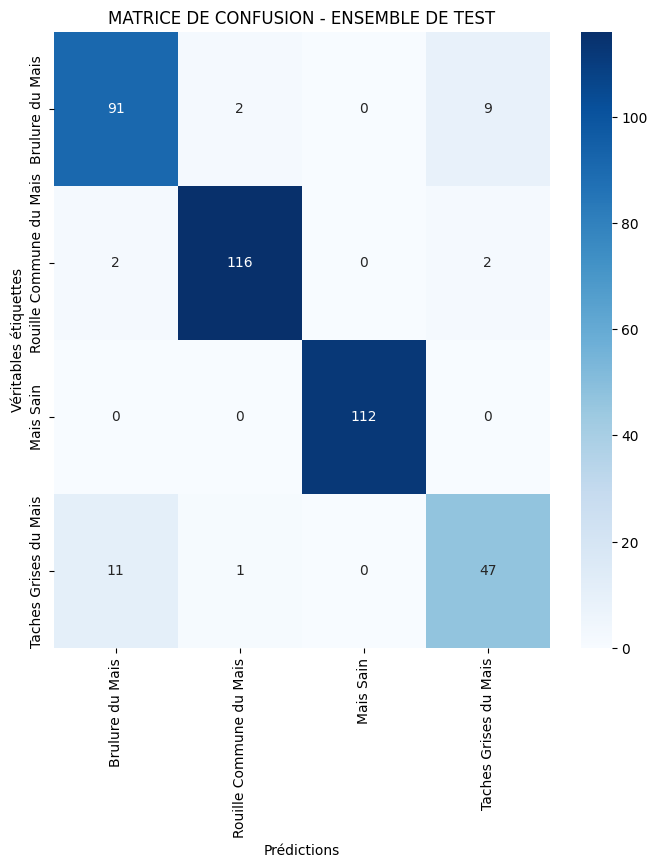


📉 COURBES D'APPRENTISSAGE:


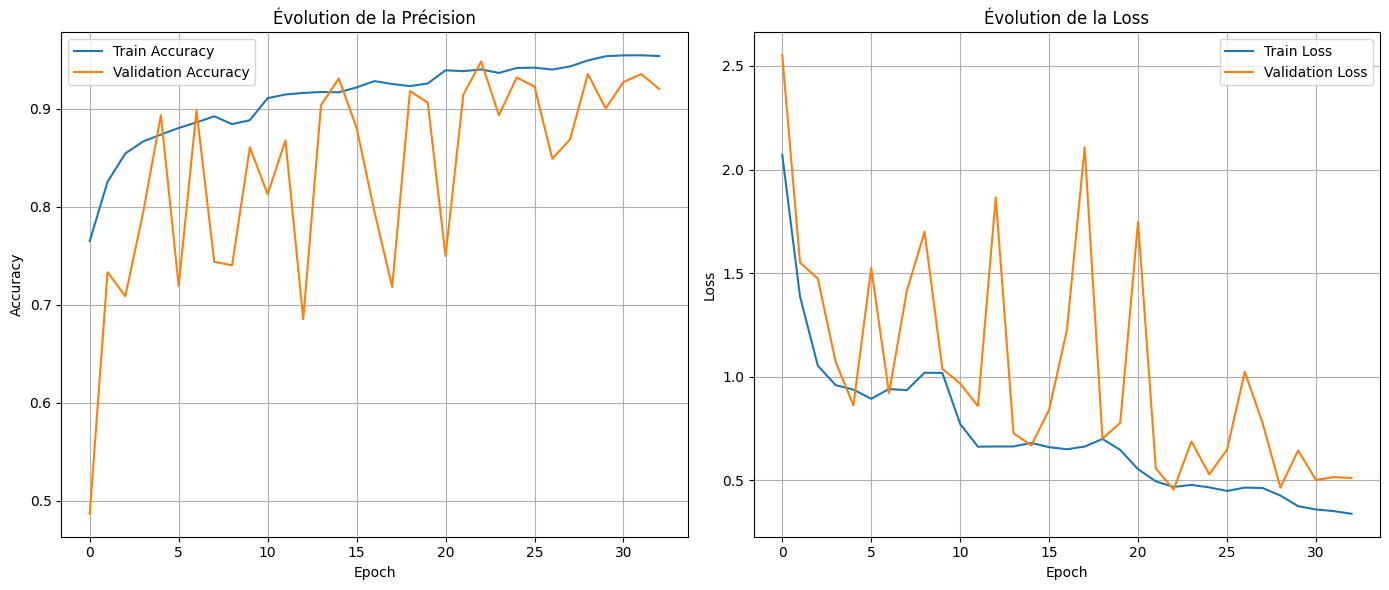


✅ Évaluation finale et analyse des résultats terminées.

--- Partie 5 terminée ---


In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

print("## Partie 5 : Évaluation Finale et Analyse des Résultats")

# ================= CHARGER LE MEILLEUR MODÈLE =================
# Chemin vers le meilleur modèle sauvegardé pendant l'entraînement (Partie 4).
checkpoint_path = '/content/drive/MyDrive/simple_cnn_training/best_simple_cnn_model.keras' # Assurez-vous que ce chemin est correct

# Tente de charger le modèle.
if os.path.exists(checkpoint_path):
    print(f"Chargement du meilleur modèle depuis: {checkpoint_path}")
    model = tf.keras.models.load_model(checkpoint_path)
    print("✅ Modèle chargé.")
else:
    print(f"❌ ERREUR: Modèle introuvable à {checkpoint_path}")
    print("Veuillez vous assurer que la Partie 4 (Entraînement) a été exécutée et a sauvegardé le modèle.")
    raise FileNotFoundError("Modèle entraîné non trouvé pour l'évaluation.")


# ================= ÉVALUATION SUR L'ENSEMBLE DE TEST =================
print("\n Évaluation sur l'ensemble de TEST...")

# Assurez-vous que le test_generator et steps_per_epoch_test sont définis (Partie 2).
if 'test_generator' not in locals() or 'steps_per_epoch_test' not in locals():
     print("❌ ERREUR: test_generator ou steps_per_epoch_test non trouvé. Veuillez exécuter la Partie 2.")
     raise NameError("Variables de données ou de steps manquantes.")


test_loss, test_acc = model.evaluate(test_generator, steps=steps_per_epoch_test, verbose=1)
print(f"\n📊 Précision finale sur l'ensemble de TEST: {test_acc:.4f}")
print(f"   Loss finale sur l'ensemble de TEST: {test_loss:.4f}")


# ================= RAPPORT DE CLASSIFICATION =================
print("\n📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ:")

test_generator.reset() # Important pour s'assurer que les prédictions correspondent aux vraies étiquettes
y_pred_probs = model.predict(test_generator, steps=steps_per_epoch_test, verbose=1)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

y_true_classes = test_generator.classes

# Obtenir les noms des classes pour le rapport et la matrice (définis en Partie 2).
# Modification pour utiliser des noms de classes plus lisibles
class_names = ['Brulure du Mais', 'Rouille Commune du Mais', 'Mais Sain', 'Taches Grises du Mais'] # Noms mis à jour

if 'class_names' not in locals():
     print("❌ ERREUR: class_names non trouvé. Veuillez exécuter la Partie 2.")
     # Tente de récupérer les noms de classes depuis le générateur de test si possible
     if hasattr(test_generator, 'class_indices'):
          class_names = list(test_generator.class_indices.keys())
          print("   Récupération des noms de classes depuis test_generator réussie.")
     else:
          # Si même le générateur n'a pas class_indices, utiliser des noms génériques basés sur le nombre de classes prédites/réelles
          num_classes_detected = len(np.unique(y_true_classes)) if len(np.unique(y_true_classes)) > 0 else model.output_shape[-1]
          class_names = [f'class_{i}' for i in range(num_classes_detected)]
          print(f"   Noms de classes non trouvés, utilisation de noms génériques: {class_names}")


print(classification_report(y_true_classes,
                            y_pred_classes,
                            target_names=class_names))


# ================= MATRICE DE CONFUSION =================
print("\n📈 MATRICE DE CONFUSION:")
cm = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(max(8, len(class_names)*1.2), max(8, len(class_names)*1.2))) # Ajuste la taille en fonction du nombre de classes
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Prédictions')
plt.ylabel('Véritables étiquettes')
plt.title('MATRICE DE CONFUSION - ENSEMBLE DE TEST')
plt.savefig('/content/drive/MyDrive/simple_cnn_training/simple_cnn_confusion_matrix.png') # Sauvegarde la matrice
plt.show()


# ================= COURBES D'APPRENTISSAGE =================
print("\n📉 COURBES D'APPRENTISSAGE:")

log_path = '/content/drive/MyDrive/simple_cnn_training/simple_cnn_training_log.csv' # Chemin du log CSV (Partie 4)

if os.path.exists(log_path):
    try:
        history_df = pd.read_csv(log_path)

        if not history_df.empty and 'epoch' in history_df.columns and ('accuracy' in history_df.columns or 'val_accuracy' in history_df.columns) and ('loss' in history_df.columns or 'val_loss' in history_df.columns):
            plt.figure(figsize=(14, 6))

            # Courbe de précision
            plt.subplot(1, 2, 1)
            if 'accuracy' in history_df.columns:
                plt.plot(history_df['epoch'], history_df['accuracy'], label='Train Accuracy')
            if 'val_accuracy' in history_df.columns:
                plt.plot(history_df['epoch'], history_df['val_accuracy'], label='Validation Accuracy')
            plt.title('Évolution de la Précision')
            plt.xlabel('Epoch')
            plt.ylabel('Accuracy')
            plt.legend()
            plt.grid(True)

            # Courbe de loss
            plt.subplot(1, 2, 2)
            if 'loss' in history_df.columns:
                plt.plot(history_df['epoch'], history_df['loss'], label='Train Loss')
            if 'val_loss' in history_df.columns:
                plt.plot(history_df['epoch'], history_df['val_loss'], label='Validation Loss')
            plt.title('Évolution de la Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.legend()
            plt.grid(True)

            plt.tight_layout()
            plt.savefig('/content/drive/MyDrive/simple_cnn_training/simple_cnn_training_history.png') # Sauvegarde les courbes
            plt.show()
        else:
            print("⚠️ Données de log insuffisantes ou format incorrect pour tracer les courbes d'apprentissage.")
            print("Veuillez vous assurer que le fichier log existe et contient les colonnes 'epoch', 'accuracy', 'val_accuracy', 'loss', 'val_loss'.")
            print("Colonnes disponibles dans le log:", history_df.columns.tolist() if not history_df.empty else "DataFrame vide")

    except Exception as e:
        print(f"⚠️ Erreur lors du chargement ou de l'analyse du fichier log CSV: {e}")
        print("Impossible de tracer les courbes d'apprentissage.")

else:
    print(f"⚠️ Fichier log non trouvé à {log_path}.")
    print("Impossible de tracer les courbes d'apprentissage.")


print("\n✅ Évaluation finale et analyse des résultats terminées.")

print("\n--- Partie 5 terminée ---")

# **Partie 7 : Prédiction sur de Nouvelles Images**

## Cellule de Test Individuel du Modèle
Chargement du modèle depuis: /content/drive/MyDrive/simple_cnn_training/best_simple_cnn_model.keras
✅ Modèle chargé avec succès.
Classes utilisées par le modèle: ['Brulure du Mais', 'Rouille Commune du Mais', 'Mais Sain', 'Taches Grises du Mais']

Chargement de l'image pour test depuis: /content/drive/MyDrive/images/img1.JPG
✅ Image chargée et préparée.


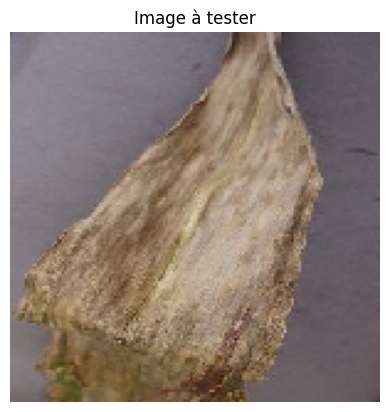


🔬 Effectuer la prédiction...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 875ms/step

Résultats de la prédiction :
Probabilités par classe : [9.9956948e-01 2.1624564e-07 2.4909954e-05 4.0543452e-04]
Classe prédite (indice) : 0
Classe prédite (nom) : Brulure du Mais
Confiance de la prédiction : 0.9996

Interprétation :
Confidence suffisante (99.96%) pour la classe 'Brulure du Mais'.
L'image semble représenter une feuille atteinte de 'Brulure du Mais'.
Détails : Détails sur la Brûlure du Maïs : Caractérisée par des lésions allongées et nécrotiques, souvent le long des nervitures.

--- Cellule de Test Individuel terminée ---


In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image # Importe le module image pour charger l'image
import matplotlib.pyplot as plt
import os

print("## Cellule de Test Individuel du Modèle")

# ================= CHARGER LE MODÈLE ENTRAÎNÉ =================
# Chemin vers le meilleur modèle sauvegardé pendant l'entraînement (Partie 4).
# Assurez-vous que ce chemin est correct.
checkpoint_path = '/content/drive/MyDrive/simple_cnn_training/best_simple_cnn_model.keras'

# Tente de charger le modèle.
if os.path.exists(checkpoint_path):
    print(f"Chargement du modèle depuis: {checkpoint_path}")
    model = tf.keras.models.load_model(checkpoint_path)
    print("✅ Modèle chargé avec succès.")
else:
    print(f"❌ ERREUR: Modèle introuvable à {checkpoint_path}")
    print("Veuillez vérifier le chemin ou ré-exécuter la Partie 4 pour sauvegarder le modèle.")
    # Vous pouvez ajouter une instruction 'raise FileNotFoundError(...)' ici si vous voulez arrêter l'exécution en cas d'erreur.


# ================= CONFIGURATION =================
# La taille d'image attendue par votre modèle (définie en Partie 2)
img_size = (150, 150)
# Les noms des classes dans l'ordre où le modèle les a apprises (définis en Partie 2)
# Assurez-vous que 'class_names' est disponible, sinon définissez-le manuellement
if 'class_names' not in locals():
     print("⚠️ class_names non trouvé. Tente de récupérer depuis le modèle ou le générateur...")
     # Tenter de récupérer depuis le générateur de test si défini
     try: # Added try block here
         if 'test_generator' in locals() and hasattr(test_generator, 'class_indices'):
              class_names = list(test_generator.class_indices.keys())
              print("   Récupération des noms de classes depuis test_generator réussie.")
         else:
              # Fallback si test_generator n'est pas dispo ou n'a pas class_indices
              # Vous devriez idéalement définir class_names manuellement si Partie 2 n'est pas exécutée
              print("   ⚠️ class_names non trouvé et récupération automatique échouée. Utilisation de noms génériques.")
              num_classes_from_model = model.output_shape[-1] if model else 4 # Essaie de deviner le nombre de classes
              class_names = [f'class_{i}' for i in range(num_classes_from_model)]
     except Exception as e: # Added except block here
         print(f"   ⚠️ Erreur lors de la tentative de récupération automatique de class_names: {e}")
         num_classes_from_model = model.output_shape[-1] if model else 4
         class_names = [f'class_{i}' for i in range(num_classes_from_model)]

# >>> AJOUTEZ VOTRE LISTE DE NOUVEAUX NOMS DE CLASSES ICI <<<
# Assurez-vous que l'ordre correspond à l'ordre original des classes détectées:
# ['Corn___ brûlure', 'Corn___rouille_commune', 'Corn___saine', 'Corn___taches']
class_names = ['Brulure du Mais', 'Rouille Commune du Mais', 'Mais Sain', 'Taches Grises du Mais'] # Noms mis à jour pour l'affichage


print("Classes utilisées par le modèle:", class_names)

# Seuil de confiance pour considérer une prédiction comme valide
confidence_threshold = 0.70 # 70% - Vous pouvez ajuster ce seuil

# ================= CHARGER ET PRÉPARER L'IMAGE =================
# REMPLACEZ CE CHEMIN par le chemin de l'image que vous voulez tester.
# L'image doit être accessible par Colab (téléchargée ou sur Drive).
image_path_to_test = '/content/drive/MyDrive/images/img1.JPG' # <-- Exemple : remplacez par votre chemin


if model is None:
    print("Impossible de continuer sans un modèle chargé.")
elif not os.path.exists(image_path_to_test):
    print(f"\n❌ ERREUR: L'image à tester est introuvable à: {image_path_to_test}")
    print("Veuillez vérifier le chemin de l'image ou assurez-vous qu'elle est téléchargée/accessible dans Colab.")
else:
    print(f"\nChargement de l'image pour test depuis: {image_path_to_test}")
    try:
        # Charger l'image et la redimensionner
        img = image.load_img(image_path_to_test, target_size=img_size)
        # Convertir l'image en tableau numpy
        img_array = image.img_to_array(img)
        # Ajouter une dimension pour correspondre au format attendu par le modèle (batch size de 1)
        img_array = np.expand_dims(img_array, axis=0)
        # Normaliser l'image (comme fait pendant la préparation des données)
        img_array /= 255.0

        print("✅ Image chargée et préparée.")

        # Optionnel : Afficher l'image chargée
        plt.imshow(img)
        plt.title("Image à tester")
        plt.axis('off')
        plt.show()


        # ================= EFFECTUER LA PRÉDICTION =================
        print("\n🔬 Effectuer la prédiction...")
        predictions = model.predict(img_array)
        # Obtenir les probabilités de chaque classe
        prediction_probs = predictions[0]
        # Obtenir l'indice de la classe avec la probabilité la plus élevée
        predicted_class_index = np.argmax(prediction_probs)
        # Obtenir la probabilité de la classe prédite
        predicted_class_confidence = prediction_probs[predicted_class_index]
        # Obtenir le nom de la classe prédite
        predicted_class_name = class_names[predicted_class_index] # Utilise la liste class_names mise à jour

        print("\nRésultats de la prédiction :")
        print(f"Probabilités par classe : {prediction_probs}")
        print(f"Classe prédite (indice) : {predicted_class_index}")
        print(f"Classe prédite (nom) : {predicted_class_name}")
        print(f"Confiance de la prédiction : {predicted_class_confidence:.4f}")


        # ================= INTERPRÉTER LES RÉSULTATS (AVEC SEUIL DE CONFIDENCE) =================
        print("\nInterprétation :")
        if predicted_class_confidence >= confidence_threshold:
            print(f"Confidence suffisante ({predicted_class_confidence:.2%}) pour la classe '{predicted_class_name}'.")
            if predicted_class_name == 'Mais Sain': # Comparaison avec le nouveau nom
                print("L'image semble représenter une feuille saine.")
            else:
                print(f"L'image semble représenter une feuille atteinte de '{predicted_class_name}'.")
                # TODO: Ajouter ici la logique pour afficher plus de détails sur la maladie si nécessaire.
                # Vous pouvez utiliser un dictionnaire ou une autre structure pour stocker les descriptions.
                disease_details = {
                    'Brulure du Mais': "Détails sur la Brûlure du Maïs : Caractérisée par des lésions allongées et nécrotiques, souvent le long des nervitures.",
                    'Rouille Commune du Mais': "Détails sur la Rouille Commune du Maïs : Se présente sous forme de petites pustules de couleur rouille sur les feuilles.",
                    'Taches Grises du Mais': "Détails sur la Tache Grise du Maïs : Causée par un champignon, elle provoque des lésions rectangulaires grises avec des bords bruns.",
                    # Ajoutez d'autres classes de maladies ici si nécessaire
                }
                if predicted_class_name in disease_details:
                    print(f"Détails : {disease_details[predicted_class_name]}")
                else:
                    print("Détails sur cette maladie non disponibles.")

        else:
            print(f"Confidence faible ({predicted_class_confidence:.2%}) pour la classe prédite.")
            print("Il est possible que l'image ne soit pas une feuille, qu'elle soit d'une classe non entraînée, ou que le modèle ne soit pas certain de sa classification.")

    except Exception as e:
        print(f"❌ Erreur lors du traitement de l'image ou de la prédiction: {e}")


print("\n--- Cellule de Test Individuel terminée ---")

In [ ]:
import tensorflow as tf
import os

print("## Cellule de Conversion du Modèle en TensorFlow Lite")

# ================= CHARGER LE MODÈLE ENTRAÎNÉ =================
# Chemin vers le meilleur modèle sauvegardé pendant l'entraînement (Partie 4).
# Assurez-vous que ce chemin est correct.
# Nous allons charger le modèle sauvegardé au format .keras
model_path = '/content/drive/MyDrive/simple_cnn_training/best_simple_cnn_model.keras'

# Tente de charger le modèle.
if os.path.exists(model_path):
    print(f"Chargement du modèle TensorFlow depuis: {model_path}")
    model = tf.keras.models.load_model(model_path)
    print("✅ Modèle TensorFlow chargé avec succès.")
else:
    print(f"❌ ERREUR: Modèle TensorFlow introuvable à {model_path}")
    print("Veuillez vérifier le chemin ou assurez-vous que la Partie 4 (Entraînement) a sauvegardé le modèle.")
    raise FileNotFoundError("Modèle TensorFlow non trouvé pour la conversion.")

# ================= CONFIGURER ET EFFECTUER LA CONVERSION TFLITE =================
print("\nConfiguration et conversion en TensorFlow Lite...")

# Initialiser le convertisseur TFLite
# On convertit le modèle TensorFlow (chargé en mémoire)
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Optionnel : Appliquer des optimisations (par exemple, optimisation par défaut qui inclut la quantification du poids)
# Ceci réduit la taille du modèle et peut accélérer l'inférence sur mobile.
# Attention : La quantification peut parfois affecter légèrement la précision.
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Autre option courante : spécifier les types d'entrée/sortie (peut aider avec certains hardwares/délégués)
# converter.target_spec.supported_types = [tf.float16] # Pour la quantification en float16
# converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS] # Si votre modèle utilise des opérations TensorFlow non standard en TFLite

print("Configuration du convertisseur TFLite terminée.")

# Effectuer la conversion
try:
    tflite_model = converter.convert()
    print("✅ Conversion en TensorFlow Lite réussie.")
except Exception as e:
    print(f"❌ ERREUR lors de la conversion TFLite: {e}")
    print("La conversion a échoué.")
    tflite_model = None # S'assurer que tflite_model est None en cas d'erreur

# ================= SAUVEGARDER LE MODÈLE TFLITE =================
if tflite_model is not None:
    # Chemin où sauvegarder le fichier .tflite
    tflite_model_path = '/content/drive/MyDrive/simple_cnn_training/simple_cnn_model.tflite' # Vous pouvez changer le nom

    try:
        with open(tflite_model_path, 'wb') as f:
            f.write(tflite_model)
        print(f"\n✅ Modèle TensorFlow Lite sauvegardé avec succès à : {tflite_model_path}")
        print("Ce fichier (.tflite) est celui que vous intégrerez dans votre application Android.")
        print(f"Taille du fichier : {os.path.getsize(tflite_model_path)} bytes")
    except Exception as e:
        print(f"❌ ERREUR lors de la sauvegarde du fichier .tflite: {e}")
        print(f"La sauvegarde à {tflite_model_path} a échoué.")

else:
    print("\nImpossible de sauvegarder le modèle TFLite car la conversion a échoué.")


print("\n--- Cellule de Conversion terminée ---")

## Cellule de Conversion du Modèle en TensorFlow Lite
Chargement du modèle TensorFlow depuis: /content/drive/MyDrive/simple_cnn_training/best_simple_cnn_model.keras
✅ Modèle TensorFlow chargé avec succès.

Configuration et conversion en TensorFlow Lite...
Configuration du convertisseur TFLite terminée.
Saved artifact at '/tmp/tmporq2367d'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  138309555043600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138312095745616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138312095749072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138312095746768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138312095747728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138312095745424: TensorSpec(shape=(), dtype=tf.resource, name

In [ ]:
import tensorflow as tf
import os

tflite_model_path = '/content/drive/MyDrive/simple_cnn_training/simple_cnn_model.tflite'

print(f"Tentative de chargement du modèle TFLite depuis : {tflite_model_path}")

if os.path.exists(tflite_model_path):
    try:
        # Charge le modèle TFLite
        interpreter = tf.lite.Interpreter(model_path=tflite_model_path)
        # Alloue les tenseurs nécessaires
        interpreter.allocate_tensors()
        print("✅ Le modèle TFLite a été chargé avec succès. Le fichier semble valide et lisible.")
        # Vous pouvez optionally imprimer les détails d'entrée/sortie
        # print("\nDétails d'entrée:")
        # for i in interpreter.get_input_details():
        #     print(i)
        # print("\nDétails de sortie:")
        # for o in interpreter.get_output_details():
        #     print(o)

    except Exception as e:
        print(f"❌ Erreur lors du chargement du modèle TFLite : {e}")
        print("Le fichier .tflite pourrait être corrompu ou n'est pas un modèle TFLite valide.")
else:
    print(f"❌ Le fichier modèle TFLite est introuvable à l'emplacement : {tflite_model_path}")
    print("Veuillez vérifier le chemin ou assurez-vous que la Partie 8 a bien sauvegardé le modèle .tflite.")

Tentative de chargement du modèle TFLite depuis : /content/drive/MyDrive/simple_cnn_training/simple_cnn_model.tflite
✅ Le modèle TFLite a été chargé avec succès. Le fichier semble valide et lisible.
